## Challenge 3: Can You Change the Correlation?

### Prediction

**Original Bell-state circuit:** I predict that measurement outcomes `00` and `11` will dominate, with approximately 50% probability each.

**Modified circuit:** I added one X gate to qubit 1 after the CNOT gate. I predict that outcomes `01` and `10` will dominate, with approximately 50% probability each.

### Explanation

The original Bell-state circuit creates strong correlations between the two qubits. When measured, they produce matching outcomes: `00` or `11`.

Adding an X gate to qubit 1 flips its measurement result. Therefore, the modified circuit produces opposite outcomes: `01` or `10`.

This demonstrates how changing a single quantum gate can change the correlation pattern observed when measuring an entangled pair of qubits.

Original Bell-state circuit:
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 

Modified circuit:
     ┌───┐          ┌─┐   
q_0: ┤ H ├──■───────┤M├───
     └───┘┌─┴─┐┌───┐└╥┘┌─┐
q_1: ─────┤ X ├┤ X ├─╫─┤M├
          └───┘└───┘ ║ └╥┘
c: 2/════════════════╩══╩═
                     0  1 

Original Bell State
Measurement results: {'00': 47, '11': 53}
Total shots: 100


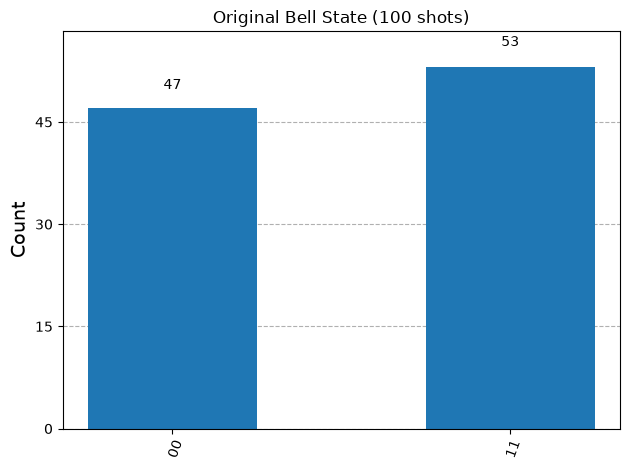


Modified Bell State
Measurement results: {'01': 51, '10': 49}
Total shots: 100


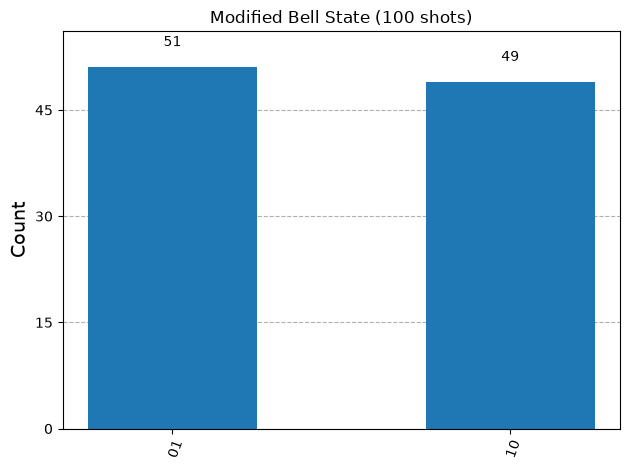

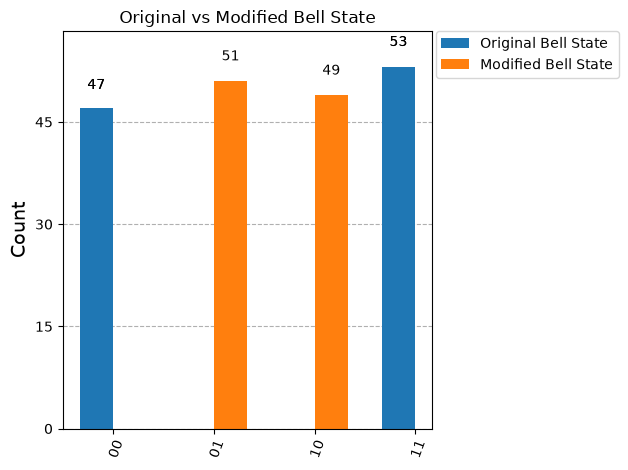

In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from IPython.display import display

simulator = AerSimulator()

# Original Bell-state circuit
original = QuantumCircuit(2, 2)
original.h(0)
original.cx(0, 1)
original.measure([0, 1], [0, 1])

# Modified circuit: add one X gate to qubit 1
modified = QuantumCircuit(2, 2)
modified.h(0)
modified.cx(0, 1)
modified.x(1)
modified.measure([0, 1], [0, 1])

# Display both circuits
print("Original Bell-state circuit:")
print(original.draw(output="text"))

print("\nModified circuit:")
print(modified.draw(output="text"))

# Execute both circuits for 100 shots
circuits = {
    "Original Bell State": original,
    "Modified Bell State": modified
}

results = {}

for name, circuit in circuits.items():
    result = simulator.run(circuit, shots=100).result()
    counts = result.get_counts()
    results[name] = dict(counts)

    print(f"\n{name}")
    print("Measurement results:", counts)
    print("Total shots:", sum(counts.values()))

    display(plot_histogram(
        counts,
        title=f"{name} (100 shots)"
    ))

# Compare both circuits
display(plot_histogram(
    list(results.values()),
    legend=list(results.keys()),
    title="Original vs Modified Bell State"
))

### Actual Results

**Original Bell-state circuit**
- `00`: 47 measurements
- `11`: 53 measurements
- Total: 100 shots

**Modified Bell-state circuit**
- `01`: 51 measurements
- `10`: 49 measurements
- Total: 100 shots

### Comparison and Conclusion

The original Bell-state circuit produced matching outcomes, `00` and `11`, with counts of 47 and 53. After adding an X gate to qubit 1, the modified circuit produced opposite outcomes, `01` and `10`, with counts of 51 and 49.

The experimental results agree with the predictions. This demonstrates that modifying one quantum gate can change the correlations between measurement outcomes of two entangled qubits.